In [ ]:
#**Image Forgery Classification Method 3**


In [ ]:
import numpy as np
import pandas as pd
import os
import re
import pathlib
from PIL import Image, ImageEnhance, ImageChops
import random
from shutil import copyfile
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from sklearn.metrics import *
from keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle as pkl
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, add, GlobalAveragePooling2D, Dense, concatenate, Flatten
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import pathlib

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


### Data Preparation ###

In [ ]:

import os, re, sys, hashlib, subprocess, pathlib
import numpy as np
import pandas as pd
from PIL import Image

try:
    import imagehash
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imagehash'], check=True)
    import imagehash

path     = '/content/gdrive/MyDrive/CASIA_2'
data_dir = pathlib.Path(path)
OUT_DIR  = '/content/gdrive/MyDrive/leakage_check'
PHASH_THRESHOLD = 4
IMG_EXT  = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')
os.makedirs(OUT_DIR, exist_ok=True)

CLASSES = sorted(d.name for d in data_dir.iterdir() if d.is_dir() and not d.name.startswith('.'))
print('Classes:', CLASSES)

rows = []
for label, cls in enumerate(CLASSES):
    for p in sorted((data_dir / cls).iterdir()):
        if p.is_file() and not p.name.startswith('.'):
            rows.append({'fname': p.name, 'label_name': cls, 'label': label,
                         'orig_path': str(p), 'ext': p.suffix.lower()})
df = pd.DataFrame(rows)

other = df[~df.ext.isin(IMG_EXT)]
if len(other):
    print(f'Non-image files excluded: {len(other)}  e.g. {other.fname.tolist()[:5]}')
df = df[df.ext.isin(IMG_EXT)].reset_index(drop=True)

image_count = len(df)
print('Total images:', image_count)
print(pd.crosstab(df.label_name, df.ext, margins=True))

Classes: ['Authentic', 'Tampered']
Total images: 2329
ext         .jpg   All
label_name            
Authentic   1171  1171
Tampered    1158  1158
All         2329  2329


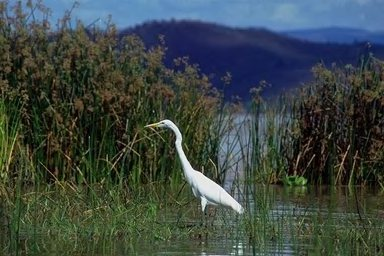

In [ ]:
# View an image
Image.open(df.orig_path[1])

In [ ]:
def get_data_distr(base_dir):
  label = []       #  Assign all label
  images_path = [] # Get all images path
  all_images = []  # Check all images name
  idx = 0          # index
  img_label = []   # Assign image label

  for directory in os.listdir(base_dir):
    if '.' != directory[0] and os.path.isdir(os.path.join(base_dir,directory)):
      label.append(directory)
      for img in os.listdir(os.path.join(base_dir,directory)):
          if len(re.findall('.png',img.lower())) != 0 or len(re.findall('.jpg',img.lower())) != 0 or len(re.findall('.tif',img.lower())) != 0:
              img_path = os.path.join(os.path.join(base_dir,directory),img)
              all_images.append(img)
              images_path.append(img_path)
              img_label.append(directory)
  # create dataframe
  data =pd.DataFrame({'image':images_path,'label':img_label})
  data_label = data['label'].value_counts()
  plt.figure()
  sns.barplot(x = data_label.index, y = data_label)
  print(f"Total Images class [0]:{data_label[0]}")
  print(f"Total Images class [1]:{data_label[1]}")

Total Images class [0]:1171
Total Images class [1]:1158


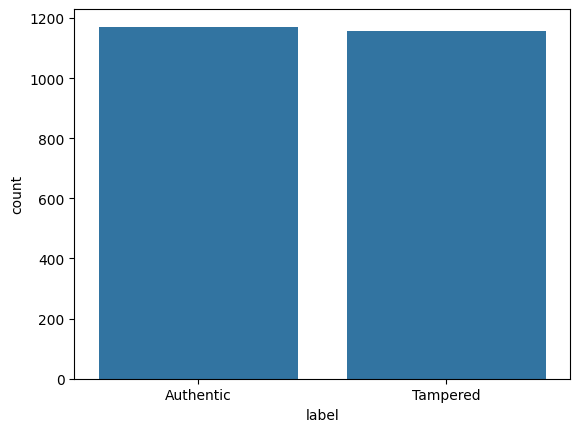

In [ ]:
get_data_distr(data_dir)

In [ ]:
def convert_to_cea_image(path, quality):
    '''
    Convert image to CEA format
    '''
    temp_filename = 'temp_file_name.jpg'
    cea_filename = 'temp_cea.png'

    image = Image.open(path).convert('RGB')
    image.save(temp_filename, 'JPEG', quality = quality)
    temp_image = Image.open(temp_filename)

    cea_image = ImageChops.difference(image, temp_image)

    extrema = cea_image.getextrema()
    max_diff = max([ex[1] for ex in extrema])
    if max_diff == 0:
        max_diff = 1
    scale = 255.0 / max_diff

    cea_image = ImageEnhance.Brightness(cea_image).enhance(scale)

    return cea_image

In [ ]:
def view_cea(p):
  '''
  View CEA of image at different quality levels.
  '''
  orig = cv2.imread(p)
  orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB) / 255.0
  init_val = 100
  columns = 3
  rows = 3

  fig=plt.figure(figsize=(15, 10))
  for i in range(1, columns*rows +1):
      quality=init_val - (i-1) * 3
      img = convert_to_cea_image(path=p, quality=quality)
      if i == 1:
          img = orig.copy()
      ax = fig.add_subplot(rows, columns, i)
      ax.title.set_text(f'q: {quality}')
      plt.imshow(img)
  plt.show()

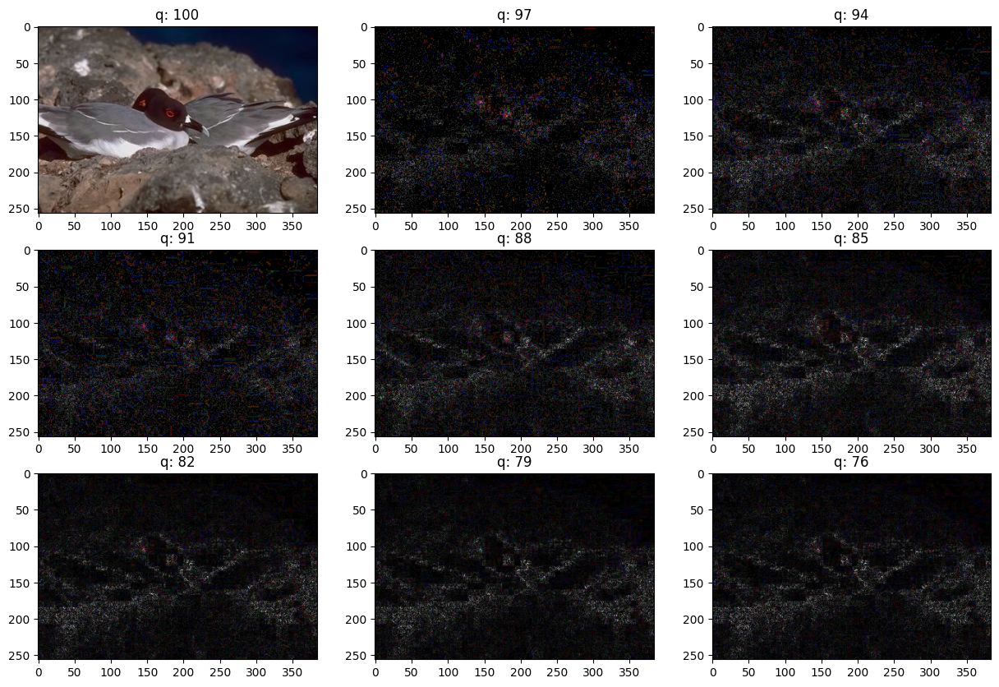

In [ ]:
Authentic_image_path = '/content/gdrive/My Drive/CASIA_2/Authentic/Au_ani_00008.jpg'
view_cea(Authentic_image_path)

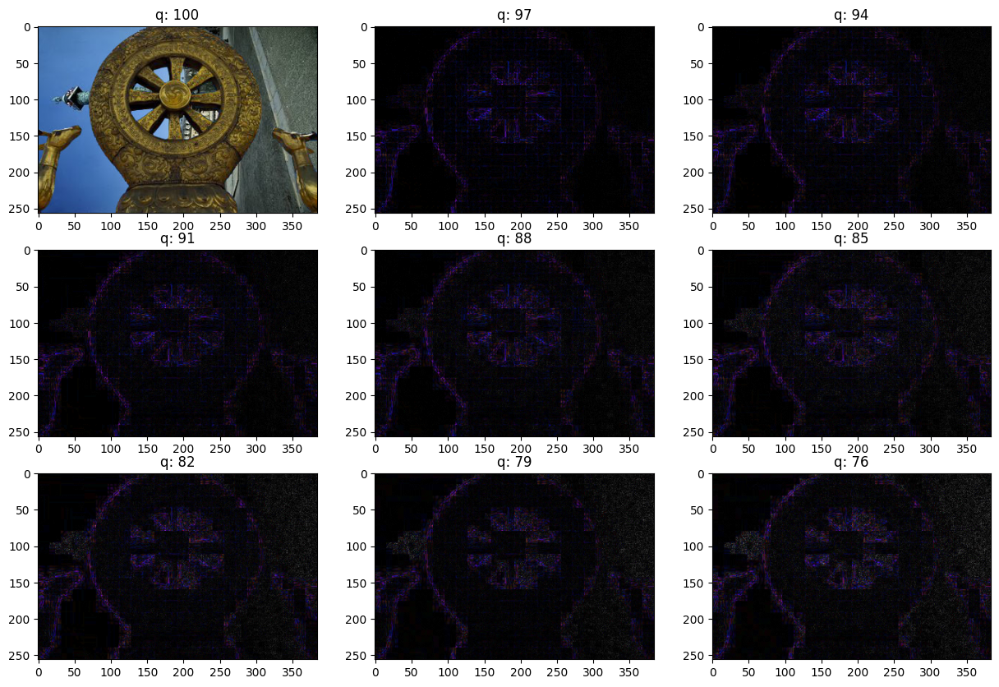

In [ ]:
Tampered_image_path = '/content/gdrive/My Drive/CASIA_2/Tampered/Tp_D_CNN_M_N_art00052_arc00030_11853.jpg'
view_cea(Tampered_image_path)

**LEAKAGE-FREE TRAIN / VALIDATION / TEST SPLIT**



In [ ]:

CACHE = os.path.join(OUT_DIR, 'image_meta_original_sha256.pkl')

def jpeg_qtable_mean(img):
    q = getattr(img, 'quantization', None)        # JPEG only
    return float(np.mean(q[0])) if q else np.nan  # lower = higher JPEG quality

if os.path.exists(CACHE):
    meta = pd.read_pickle(CACHE)
else:
    recs = []
    for i, p in enumerate(df.orig_path):
        rec = {'orig_path': p, 'ok': True, 'sha256': None, 'phash': None,
               'width': np.nan, 'height': np.nan, 'filesize': np.nan, 'qtable_mean': np.nan}
        try:
            with open(p, 'rb') as fh:
                data = fh.read()
            rec['sha256'] = hashlib.sha256(data).hexdigest()
            rec['filesize'] = len(data)
            with Image.open(p) as img:
                rec['width'], rec['height'] = img.size
                rec['qtable_mean'] = jpeg_qtable_mean(img)
                rec['phash'] = str(imagehash.phash(img.convert('RGB')))
        except Exception as e:
            rec['ok'] = False
            print('Unreadable, excluded:', os.path.basename(p), '->', e)
        recs.append(rec)
        if i % 1000 == 0:
            print(f'{i}/{len(df)}')
    meta = pd.DataFrame(recs)
    meta.to_pickle(CACHE)

df = df.merge(meta, on='orig_path', how='left')
df = df[df.ok].reset_index(drop=True)
print('Usable images:', len(df))
print(df.groupby('label_name').size().rename('images'))

Usable images: 2329
label_name
Authentic    1171
Tampered     1158
Name: images, dtype: int64


In [ ]:
# Source IDs from CASIA filenames + remove exact duplicates

def source_ids(fname):
    name = os.path.splitext(fname)[0]
    if name.startswith('Au_'):
        p = name.split('_')
        return {p[1] + p[2]} if len(p) >= 3 else {name}
    ids = set(re.findall(r'[a-z]{3}\d{5}', name))
    return ids if ids else {name}

df['src'] = df.fname.map(source_ids)

# Remove exact duplicates (same SHA-256 = byte-identical files)
before = len(df)
dup_files = df[df.duplicated(subset='sha256', keep='first')].fname.tolist()
df = df.drop_duplicates(subset='sha256', keep='first').reset_index(drop=True)
print('Removed exact duplicates:', before - len(df), dup_files)
print('Images left:', len(df))
print(df.groupby('label_name').size().rename('images'))

tp = df[df.label_name == 'Tampered']
au_ids = set().union(*df.loc[df.label_name == 'Authentic', 'src'])
print('Tampered images whose donor authentic image is in the dataset:',
      int(tp.src.map(lambda s: bool(s & au_ids)).sum()), '/', len(tp))

Removed exact duplicates: 2 ['Au_arc_30132.jpg', 'Au_arc_30162.jpg']
Images left: 2327
label_name
Authentic    1169
Tampered     1158
Name: images, dtype: int64
Tampered images whose donor authentic image is in the dataset: 215 / 1158


In [ ]:
# Exact duplicates and near-duplicates (all pairs)
sha_groups = df.groupby('sha256').agg(n=('fname', 'size'), labels=('label', 'nunique'),
                                   files=('fname', list))
exact = sha_groups[sha_groups.n > 1]
print('Exact-duplicate groups :', len(exact), f'({int(exact.n.sum())} images)')
print('  with conflicting labels:', int((exact.labels > 1).sum()))

_POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def hamming_block(a, b):
    x = np.bitwise_xor(a[:, None], b[None, :])
    return _POP[x.view(np.uint8)].reshape(x.shape + (8,)).sum(-1)

H = np.array([int(h, 16) for h in df.phash], dtype=np.uint64)
pairs = []
for s in range(0, len(H), 256):
    dist = hamming_block(H[s:s + 256], H)
    ii, jj = np.nonzero(dist <= PHASH_THRESHOLD)
    ii = ii + s
    keep = jj > ii                                  # each pair once, no self-pairs
    pairs.extend(zip(ii[keep].tolist(), jj[keep].tolist()))
near = pd.DataFrame(pairs, columns=['i', 'j'], dtype='int64')
near['file_i']  = df.fname.values[near.i]
near['file_j']  = df.fname.values[near.j]
near['label_i'] = df.label_name.values[near.i]
near['label_j'] = df.label_name.values[near.j]
print(f'Near-duplicate pairs (Hamming <= {PHASH_THRESHOLD}):', len(near))
print(near.groupby(['label_i', 'label_j']).size().rename('pairs'))
near.to_csv(os.path.join(OUT_DIR, 'near_duplicate_pairs.csv'), index=False)
exact.to_csv(os.path.join(OUT_DIR, 'exact_duplicates.csv'))

Exact-duplicate groups : 0 (0 images)
  with conflicting labels: 0
Near-duplicate pairs (Hamming <= 4): 398
label_i    label_j 
Authentic  Tampered     64
Tampered   Tampered    334
Name: pairs, dtype: int64


In [ ]:
# SETTINGS
SEED       = 42
TEST_FRAC  = 0.20          # 20% of all images -> test
VAL_FRAC   = 0.20 * 0.80   # 20% of the 80% training part -> validation (16% of all)
                           # result: train 64% | val 16% | test 20%
IMG_SIZE   = (160, 160)
BATCH_SIZE = 32

In [ ]:
# Build groups: source ID + exact duplicate + near-duplicate (union-find)
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

for i, r in enumerate(df.itertuples()):
    find(f'img:{i}')
    for s in r.src:
        union(f'img:{i}', f'src:{s}')
    union(f'img:{i}', f'sha:{r.sha256}')
for i, j in zip(near.i, near.j):
    union(f'img:{i}', f'img:{j}')

df['group'] = [find(f'img:{i}') for i in range(len(df))]
gsize = df.groupby('group').size().sort_values(ascending=False)
print(f'Groups: {len(gsize)}  |  largest: {gsize.iloc[0]} images '
      f'({100 * gsize.iloc[0] / len(df):.1f}% of data)  |  singletons: {(gsize == 1).sum()}')
print('Group size distribution:', gsize.describe().round(1).to_dict())

Groups: 1290  |  largest: 828 images (35.6% of data)  |  singletons: 1173
Group size distribution: {'count': 1290.0, 'mean': 1.8, 'std': 23.0, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 828.0}


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score


feat = pd.DataFrame({
    'is_jpeg':     df.ext.isin(['.jpg', '.jpeg']).astype(int),
    'is_tif':      df.ext.isin(['.tif', '.tiff']).astype(int),
    'width':       df.width, 'height': df.height,
    'filesize':    df.filesize, 'qtable_mean': df.qtable_mean,
}).fillna(-1)
meta_acc = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
                           feat, df.label, groups=df.group, cv=GroupKFold(n_splits=5),
                           scoring='accuracy').mean()
majority = max(df.label.mean(), 1 - df.label.mean())
med = df.groupby('label_name')[['width', 'height', 'filesize', 'qtable_mean']].median().round(1)
med['metadata_only_accuracy_%'] = round(100 * meta_acc, 2)
med['majority_baseline_%'] = round(100 * majority, 2)
med.to_csv(os.path.join(OUT_DIR, 'compression_bias_metadata.csv'))

In [ ]:

STD_LUMA = np.array([16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55,
                     14, 13, 16, 24, 40, 57, 69, 56, 14, 17, 22, 29, 51, 87, 80, 62,
                     18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
                     49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99])
def qtable_mean_for(q):
    scale = 5000 / q if q < 50 else 200 - 2 * q
    return np.clip(np.floor((STD_LUMA * scale + 50) / 100), 1, 255).mean()
Q_MEANS = np.array([qtable_mean_for(q) for q in range(1, 101)])

df['q_est'] = df.qtable_mean.map(
    lambda m: int(np.argmin(np.abs(Q_MEANS - m))) + 1 if pd.notna(m) else -1)

# Saved (not printed): number of images per estimated JPEG quality and class
pd.crosstab(df.q_est, df.label_name).to_csv(os.path.join(OUT_DIR, 'jpeg_quality_per_class.csv'))

In [ ]:
# Split by group: train / val / test

from collections import deque, defaultdict
from sklearn.model_selection import StratifiedGroupKFold

STRATEGY = 'auto'
largest_frac = gsize.iloc[0] / len(df)
mode = STRATEGY if STRATEGY != 'auto' else ('group' if largest_frac <= TEST_FRAC / 2 else 'source')

if mode == 'group':
    y, g = df.label.values, df.group.values
    sgkf = StratifiedGroupKFold(n_splits=round(1 / TEST_FRAC), shuffle=True, random_state=SEED)
    trval_idx, test_idx = next(sgkf.split(df, y, g))
    sgkf2 = StratifiedGroupKFold(n_splits=round((1 - TEST_FRAC) / VAL_FRAC),
                                 shuffle=True, random_state=SEED)
    tr_rel, va_rel = next(sgkf2.split(df.iloc[trval_idx], y[trval_idx], g[trval_idx]))
    df['split'] = 'train'
    df.loc[test_idx, 'split'] = 'test'
    df.loc[trval_idx[va_rel], 'split'] = 'val'

else:
    rng = np.random.default_rng(SEED)

    # Source nodes: one per source ID; authentic duplicates of each other share a node
    sparent = {}
    def sfind(x):
        sparent.setdefault(x, x)
        while sparent[x] != x:
            sparent[x] = sparent[sparent[x]]
            x = sparent[x]
        return x
    for s in set().union(*df.src):
        sfind(s)
    is_au = (df.label_name == 'Authentic').values
    for _, grp in df[is_au].groupby('sha256'):
        ids = [next(iter(s)) for s in grp.src]
        for o in ids[1:]:
            sparent[sfind(ids[0])] = sfind(o)
    for i, j in zip(near.i, near.j):
        if is_au[i] and is_au[j]:
            sparent[sfind(next(iter(df.src[i])))] = sfind(next(iter(df.src[j])))

    df['roots'] = df.src.map(lambda s: frozenset(sfind(x) for x in s))


    adj = defaultdict(set)
    w_cls = defaultdict(lambda: np.zeros(2))       # [authentic, tampered]
    for roots, lab in zip(df.roots, df.label):
        for r in roots:
            w_cls[r][lab] += 1 / len(roots)
        for a in roots:
            adj[a] |= roots - {a}
    dup_pairs = list(zip(near.i, near.j))
    for _, grp in df.groupby('sha256'):
        idx = grp.index.tolist()
        dup_pairs += [(idx[0], k) for k in idx[1:]]
    for i, j in dup_pairs:
        for a in df.roots[i]:
            for b in df.roots[j]:
                if a != b:
                    adj[a].add(b); adj[b].add(a)


    def grow(frac, available):
        target  = frac * np.array([n_cls[0], n_cls[1]])
        chosen, count = set(), np.zeros(2)
        pools = {k: [r for r in sorted(available) if np.argmax(w_cls[r]) == k] for k in (0, 1)}
        for k in pools:
            rng.shuffle(pools[k])
        ptr, frontier = {0: 0, 1: 0}, deque()
        while (count < target).any():
            need = count < target
            if frontier:
                n = frontier.popleft()
                if n in chosen or not (w_cls[n][need] > 0).any():
                    continue
            else:
                k = int(np.argmax((target - count) / np.maximum(target, 1)))
                n = None
                while ptr[k] < len(pools[k]):
                    cand = pools[k][ptr[k]]; ptr[k] += 1
                    if cand not in chosen:
                        n = cand; break
                if n is None:
                    break
            chosen.add(n); count += w_cls[n]
            frontier.extend(m for m in sorted(adj[n]) if m in available and m not in chosen)
        return chosen

    n_cls = np.bincount(df.label, minlength=2)
    all_roots = set(w_cls)
    test_roots = grow(TEST_FRAC, all_roots)
    val_roots  = grow(VAL_FRAC, all_roots - test_roots)
    where = {r: 'train' for r in all_roots}
    where.update({r: 'test' for r in test_roots})
    where.update({r: 'val' for r in val_roots})

    def image_split(roots):
        sets = {where[r] for r in roots}
        return sets.pop() if len(sets) == 1 else 'drop'
    df['split'] = df.roots.map(image_split)


    rank = {'train': 0, 'val': 1, 'test': 2}
    for i, j in dup_pairs:
        si, sj = df.at[i, 'split'], df.at[j, 'split']
        if 'drop' in (si, sj) or si == sj:
            continue
        df.at[i if rank[si] > rank[sj] else j, 'split'] = 'drop'

pd.crosstab(df.split, df.label_name, margins=True).to_csv(os.path.join(OUT_DIR, 'split_counts.csv'))
kept = df[df.split != 'drop']
pct = (kept.split.value_counts(normalize=True) * 100).round(1)
if pct.get('test', 0) < 100 * TEST_FRAC / 2 or pct.get('val', 0) < 100 * VAL_FRAC / 2:
    print('WARNING: val or test is far from the intended size. '
          + ("Set STRATEGY = 'source'." if mode == 'group' else 'Try another SEED.'))

In [ ]:

def nearest(query, ref, chunk=256):
    out = np.empty(len(query), dtype=np.int32)
    for s in range(0, len(query), chunk):
        out[s:s + chunk] = hamming_block(query[s:s + chunk], ref).min(1)
    return out

checks = []
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    A, B = df[df.split == a], df[df.split == b]
    n_near = int((nearest(H[B.index.values], H[A.index.values]) <= PHASH_THRESHOLD).sum())
    row = {
        'pair': f'{a} ↔ {b}',
        'shared files':      len(set(A.fname) & set(B.fname)),
        'shared source IDs': len(set().union(*A.src) & set().union(*B.src)),
        'shared SHA-256':        len(set(A.sha256) & set(B.sha256)),
        'near-duplicates':   n_near,
    }
    if mode == 'group':
        row['shared groups'] = len(set(A.group) & set(B.group))
    checks.append(row)
verify = pd.DataFrame(checks).set_index('pair')
verify['status'] = np.where(verify.sum(axis=1) == 0, 'OK', 'LEAK')
print(verify.to_string())
verify.to_csv(os.path.join(OUT_DIR, 'split_verification.csv'))
assert (verify.status == 'OK').all(), 'Leakage found — do not train on this split.'
print('\nNo leakage between train, val and test.')

              shared files  shared source IDs  shared SHA-256  near-duplicates status
pair                                                                                 
train ↔ val              0                  0               0                0     OK
train ↔ test             0                  0               0                0     OK
val ↔ test               0                  0               0                0     OK

No leakage between train, val and test.


In [ ]:
# Save the split
split_csv = os.path.join(OUT_DIR, 'grouped_split.csv')
df[['fname', 'label_name', 'label', 'orig_path', 'ext', 'q_est', 'group', 'split']] \
    .to_csv(split_csv, index=False)
print('Saved:', split_csv)

Saved: /content/gdrive/MyDrive/leakage_check/grouped_split.csv


In [ ]:
# Train / validation / test counts
kept = df[df.split != 'drop']
counts = pd.crosstab(kept.split, kept.label_name).reindex(['train', 'val', 'test'])
counts['Total'] = counts.sum(axis=1)
counts['% of kept'] = (100 * counts['Total'] / counts['Total'].sum()).round(1)
counts.loc['Total'] = counts.sum(numeric_only=True)
counts.loc['Total', '% of kept'] = 100.0

print('\nImages per set:')
print(counts.to_string())
print('\nDropped (sources in different sets):', int((df.split == 'drop').sum()))


Images per set:
label_name  Authentic  Tampered   Total  % of kept
split                                             
train           747.0     595.0  1342.0       63.4
val             187.0     140.0   327.0       15.4
test            234.0     215.0   449.0       21.2
Total          1168.0     950.0  2118.0      100.0

Dropped (sources in different sets): 209


In [ ]:
# List the dropped images
dropped = df[df.split == 'drop'].copy()

def drop_reason(roots):
    sets = sorted({where[r] for r in roots})
    if len(sets) > 1:
        return 'sources in different sets: ' + ' + '.join(sets)
    return 'near-duplicate of an image in another set'

dropped['reason']      = dropped.roots.map(drop_reason)
dropped['source_ids']  = dropped.src.map(lambda s: ', '.join(sorted(s)))


partner = {}
for i, j in zip(near.i, near.j):
    for a, b in ((i, j), (j, i)):
        if df.at[a, 'split'] == 'drop' and df.at[b, 'split'] != 'drop':
            partner.setdefault(a, f"{df.at[b, 'fname']} ({df.at[b, 'split']})")
dropped['near_dup_partner'] = dropped.index.map(lambda k: partner.get(k, ''))

print('Dropped images by reason:')
print(dropped.groupby(['reason', 'label_name']).size().to_string())

print('\nExamples:')
print(dropped[['fname', 'label_name', 'source_ids', 'reason', 'near_dup_partner']]
      .head(15).to_string(index=False))

dropped[['fname', 'label_name', 'source_ids', 'reason', 'near_dup_partner']] \
    .to_csv(os.path.join(OUT_DIR, 'dropped_images.csv'), index=False)
print('\nFull list saved:', os.path.join(OUT_DIR, 'dropped_images.csv'))

Dropped images by reason:
reason                                     label_name
near-duplicate of an image in another set  Authentic       1
sources in different sets: test + train    Tampered      114
sources in different sets: test + val      Tampered       40
sources in different sets: train + val     Tampered       54

Examples:
                                   fname label_name         source_ids                                    reason                                 near_dup_partner
                        Au_ani_30741.jpg  Authentic           ani30741 near-duplicate of an image in another set Tp_S_CNN_S_N_ind00096_ind00096_10659.jpg (train)
Tp_D_CNN_M_N_ani00052_ani00054_11130.jpg   Tampered ani00052, ani00054   sources in different sets: test + train                                                 
Tp_D_CNN_M_N_art00052_arc00030_11853.jpg   Tampered arc00030, art00052   sources in different sets: test + train                                                 
Tp_D_CNN_M_N_nat0

**CEA CONVERSION (after splitting)**

Each image in the training, validation and test sets is converted to its CEA representation and stored in a separate folder per set.

In [ ]:
def image_to_cea(path, quality, resave_path):
    ''' Gets images specified as path and resaves it at a new path resave_path at specified quality'''
    try:
        # Check if the file format is supported (JPEG or PNG)
        if path.endswith('jpg') or path.endswith('jpeg') or path.endswith('tif'):
            # Open the image and convert it to RGB mode
            image = Image.open(path).convert('RGB')

            # Resave the image with the specified quality
            image.save('resaved.jpg', 'JPEG', quality=quality)
            resaved = Image.open('resaved.jpg')

            # Calculate the CEA (Compression Error Analysis) image by taking the difference between the original and resaved image
            cea_image = ImageChops.difference(image, resaved)

            # Get the minimum and maximum pixel values in the CEA image
            band_values = cea_image.getextrema()
            max_value = max([val[1] for val in band_values])

            # If the maximum value is 0, set it to 1 to avoid division by zero
            if max_value == 0:
                max_value = 1

            # Scale the pixel values of the CEA image to the range [0, 255]
            scale = 255.0 / max_value
            cea_image = ImageEnhance.Brightness(cea_image).enhance(scale)

            # Save the CEA image with the same filename in the specified resave path
            cea_image.save(os.path.join(resave_path, os.path.basename(path)), 'JPEG')
    except Exception as e:
        print(f'Could not convert {path} to CEA: {str(e)}')

def preprocess_data(parent_path, files, resave_path):
    ''' Loops through a directory and applies the image_to_cea function to each image in the directory'''
    for file in files:
        image_to_cea(os.path.join(parent_path, file), 90, resave_path)

In [ ]:

# Convert the train / val / test images to CEA, one folder per set
from PIL import ImageChops, ImageEnhance

CEA_QUALITY   = 90
CEA_SPLIT_DIR = '/content/gdrive/MyDrive/CASIA_2_CEA_split'   # .../train|val|test/Authentic|Tampered

split_df = pd.read_csv(os.path.join(OUT_DIR, 'grouped_split.csv'))
split_df = split_df[split_df.split != 'drop'].reset_index(drop=True)

for s in ['train', 'val', 'test']:
    for cls in CLASSES:
        os.makedirs(os.path.join(CEA_SPLIT_DIR, s, cls), exist_ok=True)


expected = {os.path.join(CEA_SPLIT_DIR, r.split, r.label_name, r.fname) for r in split_df.itertuples()}
stale = [os.path.join(CEA_SPLIT_DIR, s, c, f)
         for s in ['train', 'val', 'test'] for c in CLASSES
         for f in os.listdir(os.path.join(CEA_SPLIT_DIR, s, c))
         if os.path.join(CEA_SPLIT_DIR, s, c, f) not in expected]
for f in stale:
    os.remove(f)
print('Removed CEA files from an earlier split:', len(stale))

for i, r in enumerate(split_df.itertuples()):
    out_dir = os.path.join(CEA_SPLIT_DIR, r.split, r.label_name)
    if not os.path.exists(os.path.join(out_dir, r.fname)):      # skip if already converted
        image_to_cea(r.orig_path, CEA_QUALITY, out_dir)
    if i % 500 == 0:
        print(f'{i}/{len(split_df)}')

cea_counts = pd.DataFrame({s: {cls: len(os.listdir(os.path.join(CEA_SPLIT_DIR, s, cls)))
                               for cls in CLASSES} for s in ['train', 'val', 'test']}).T
print('CEA images per set:')
print(cea_counts)

Removed CEA files from an earlier split: 0
0/2118
500/2118
1000/2118
1500/2118
2000/2118
CEA images per set:
       Authentic  Tampered
train        747       595
val          187       140
test         234       215


In [ ]:
 #Set some parameters
batch_size = 32
img_height = 160
img_width = 160
IMG_SIZE = (img_height, img_width)

In [ ]:
# Build the train / val / test datasets from the CEA folders
import tensorflow as tf
from tensorflow.keras.applications.convnext import preprocess_input
AUTOTUNE = tf.data.AUTOTUNE

split_df['cea_path'] = [os.path.join(CEA_SPLIT_DIR, s, l, f)
                        for s, l, f in zip(split_df.split, split_df.label_name, split_df.fname)]
missing = ~split_df.cea_path.map(os.path.exists)
print('Images with no CEA file (excluded):', int(missing.sum()),
      split_df[missing].groupby(['label_name', 'ext']).size().to_dict())
split_df = split_df[~missing].reset_index(drop=True)
print(pd.crosstab(split_df.split, split_df.label_name, margins=True))

def make_ds(split, shuffle=False, sub=None):
    if sub is None:
        sub = split_df[split_df.split == split]
    ds = tf.data.Dataset.from_tensor_slices((sub.cea_path.values,
                                             sub.label.values.astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(sub), seed=SEED, reshuffle_each_iteration=True)

    def load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img = tf.image.resize(img, IMG_SIZE)   # float32 in [0, 255]
        img = preprocess_input(img)             # ConvNeXt preprocessing, applied to ALL sets
        return img, label

    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds('train', shuffle=True)
val_ds   = make_ds('val')    # monitoring during training only
test_ds  = make_ds('test')   # final evaluation, used ONCE at the end


rng_m = np.random.default_rng(SEED)
parts = []
for q, grp in split_df[split_df.split == 'test'].groupby('q_est'):
    n = grp.label.value_counts().reindex([0, 1], fill_value=0).min()
    if n > 0:
        for lab in (0, 1):
            g = grp[grp.label == lab]
            parts.append(g.iloc[rng_m.permutation(len(g))[:n]])
test_matched = pd.concat(parts) if parts else split_df.iloc[:0]
print('Quality-matched test images:', len(test_matched),
      test_matched.label_name.value_counts().to_dict())
test_matched_ds = make_ds(None, sub=test_matched) if len(test_matched) else None
class_names = CLASSES

for x, yb in train_ds.take(1):
    print('Batch:', x.shape, yb.shape, '| labels:', yb[:10].numpy())

Images with no CEA file (excluded): 0 {}
label_name  Authentic  Tampered   All
split                                
test              234       215   449
train             747       595  1342
val               187       140   327
All              1168       950  2118
Quality-matched test images: 20 {'Authentic': 10, 'Tampered': 10}
Batch: (32, 160, 160, 3) (32,) | labels: [0 1 1 1 0 0 0 1 0 0]


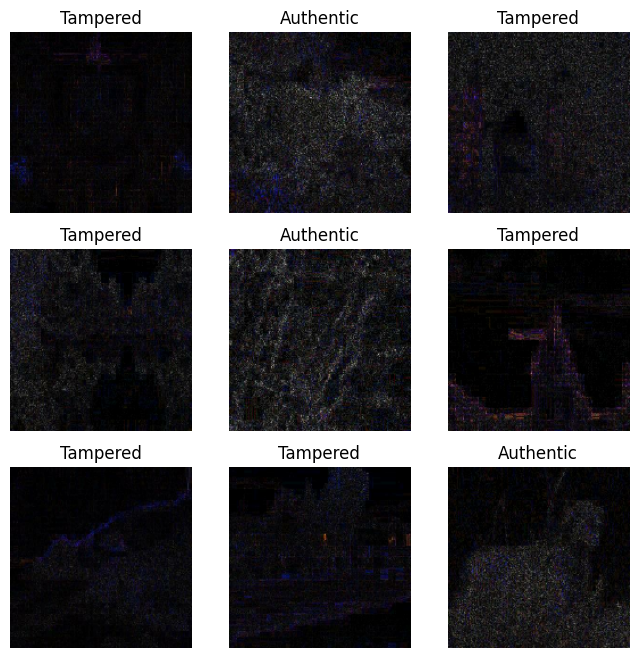

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
for images, labels in val_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [ ]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)
    print(labels_batch.shape)
    break

(32, 160, 160, 3)
(32,)


**CONFIGURE DATASET FOR PERFORMANCE**


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
# standardize
normalization_layer = layers.Rescaling(1./255)

In [ ]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0 0.41192132


In [ ]:
for images, labels in train_ds.take(1):
    print("Label shape:", labels.shape)
    print("First few labels:", labels[:5].numpy())

Label shape: (32,)
First few labels: [0 0 1 1 1]


**DATA AUGMENTATION**

In [ ]:
# Augment data
data_augmentation = tf.keras.Sequential(
  [
    layers.RandomFlip("horizontal",
                      input_shape=(img_height,
                                  img_width,
                                  3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
  ]
)

# Augmentation is applied to the TRAINING set only, after preprocessing.
# Validation and test sets are not augmented.
train_ds_aug = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                            num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

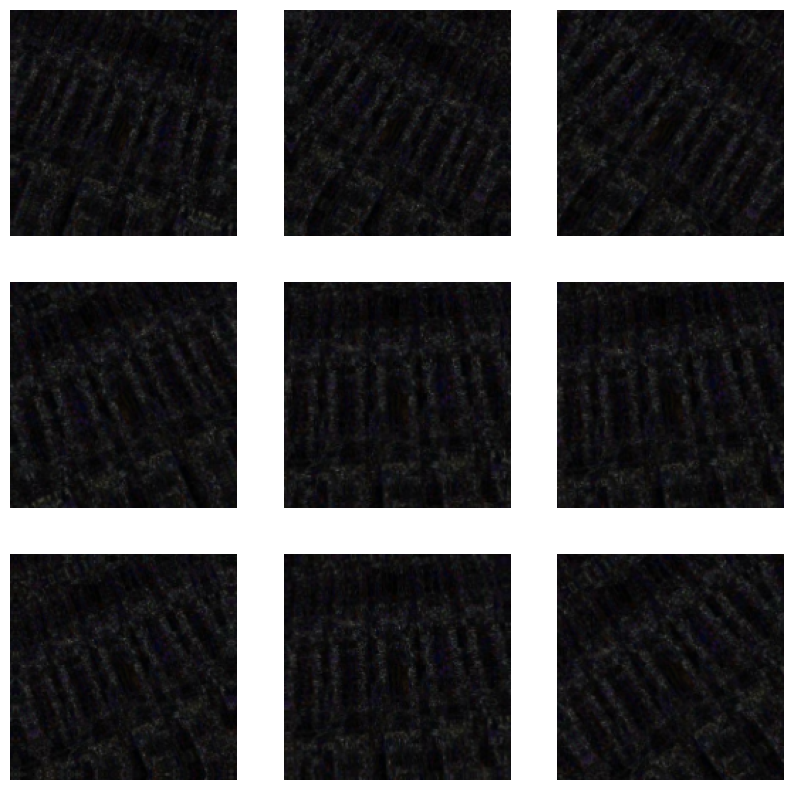

In [ ]:
for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

### NETWORK ARCHITECTURE

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (Conv2D, BatchNormalization, Activation,
                                     GlobalAveragePooling2D, Dense, Add, Dropout, Input)
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input

# Load ConvNeXt-Tiny as a frozen feature extractor
base_model = ConvNeXtTiny(include_top=False, weights='imagenet', input_shape=(160, 160, 3))
base_model.trainable = False  # Freeze ConvNeXt

# Define ResNeSt Block with Split Attention
class ResNeStBlock(tf.keras.layers.Layer):
    def __init__(self, in_channels, out_channels, radix=2, groups=1, bottleneck_width=64, **kwargs):
        super(ResNeStBlock, self).__init__(**kwargs)
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.radix = radix
        self.groups = groups
        self.bottleneck_width = bottleneck_width

        inter_channels = max(in_channels * radix // groups, 32)
        self.conv1 = Conv2D(inter_channels, kernel_size=1, strides=1, padding="same")
        self.bn1 = BatchNormalization()
        self.relu = Activation("relu")
        self.conv2 = Conv2D(inter_channels, kernel_size=3, strides=1, padding="same", groups=groups*radix)
        self.bn2 = BatchNormalization()
        self.conv3 = Conv2D(out_channels, kernel_size=1, strides=1, padding="same")
        self.bn3 = BatchNormalization()

        # Split Attention
        self.fc1 = Dense(out_channels // 2)
        self.fc2 = Dense(out_channels * radix)

        # Shortcut connection
        if in_channels != out_channels:
            self.shortcut = Conv2D(out_channels, kernel_size=1, strides=1, padding="same")
            self.shortcut_bn = BatchNormalization()
        else:
            self.shortcut = None

    def call(self, inputs):
        x = self.conv1(inputs)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        batch, h, w, c = tf.shape(x)[0], tf.shape(x)[1], tf.shape(x)[2], tf.shape(x)[3]
        x = tf.reshape(x, [batch, h, w, c])

        u = GlobalAveragePooling2D()(x)
        u = self.fc1(u)
        u = self.relu(u)
        attn = self.fc2(u)
        attn = tf.nn.softmax(tf.reshape(attn, [-1, 1, 1, self.radix, c // self.radix]), axis=3)
        attn = tf.reshape(attn, [-1, 1, 1, c])

        x = x * attn
        x = tf.reshape(x, [batch, h, w, c])

        x = self.conv3(x)
        x = self.bn3(x)

        # Apply shortcut connection
        shortcut = self.shortcut(inputs) if self.shortcut else inputs
        if self.shortcut:
            shortcut = self.shortcut_bn(shortcut)

        x = Add()([x, shortcut])
        x = self.relu(x)
        return x

    def get_config(self):
        config = super(ResNeStBlock, self).get_config()
        config.update({
            "in_channels": self.in_channels,
            "out_channels": self.out_channels,
            "radix": self.radix,
            "groups": self.groups,
            "bottleneck_width": self.bottleneck_width,
        })
        return config

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
image_batch, label_batch = next(iter(train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 5, 5, 768)


In [ ]:
from tensorflow.keras.applications.convnext import preprocess_input

In [ ]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(32, 768)


In [ ]:
prediction_layer = tf.keras.layers.Dense(1)
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1)


In [ ]:

def hybrid_convnext_resnest_model(input_shape=(160, 160, 3)):
    inputs = Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = ResNeStBlock(768, 768)(x)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    outputs = Dense(1)(x)
    return Model(inputs, outputs)

hybrid_model = hybrid_convnext_resnest_model((160, 160, 3))


In [ ]:


base_learning_rate = 0.0001

# Compile model
hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=base_learning_rate
    ),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            threshold=0.0,
            name='accuracy'
        ),
        tf.keras.metrics.AUC(
            from_logits=True,
            name='auc'
        )
    ]
)

# Calculate class weights using the training set only
n0 = int(
    (split_df[split_df.split == 'train'].label == 0).sum()
)
n1 = int(
    (split_df[split_df.split == 'train'].label == 1).sum()
)

class_weight = {
    0: (n0 + n1) / (2 * n0),
    1: (n0 + n1) / (2 * n1)
}

print('Training images - Authentic:', n0, '| Tampered:', n1)
print('Class weights:', {k: round(v, 3) for k, v in class_weight.items()})

# Reduce learning rate when validation loss plateaus
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)





Training images - Authentic: 747 | Tampered: 595
Class weights: {0: 0.898, 1: 1.128}


In [ ]:
hybrid_model.summary(expand_nested=True)

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convnext_tiny (Functional)      │ (None, 5, 5, 768)      │    27,820,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer_1 (InputLayer) │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 160, 160, 3)    │             0 │
│ convnext_tiny_prestem_normaliz… │                        │               │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ convnext_tiny_stem         │ (None, 40, 40, 96)     │         4,896 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ convnext_tiny_stem_conv │ (None, 40, 40, 96)     │         4,704 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └                         │ (None, 40, 40, 96)     │           192 │
│ convnext_tiny_stem_layernorm    │                        │               │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │         4,800 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │           192 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 384)    │        37,248 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 384)    │             0 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │        36,960 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │            96 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (LayerScale)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │             0 │
│ convnext_tiny_stage_0_block_0_… │                        │               │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └                            │ (None, 40, 40, 96)     │         4,80

 Total params: 41,997,793 (160.21 MB)

 Trainable params: 14,169,985 (54.05 MB)

 Non-trainable params: 27,827,808 (106.15 MB)

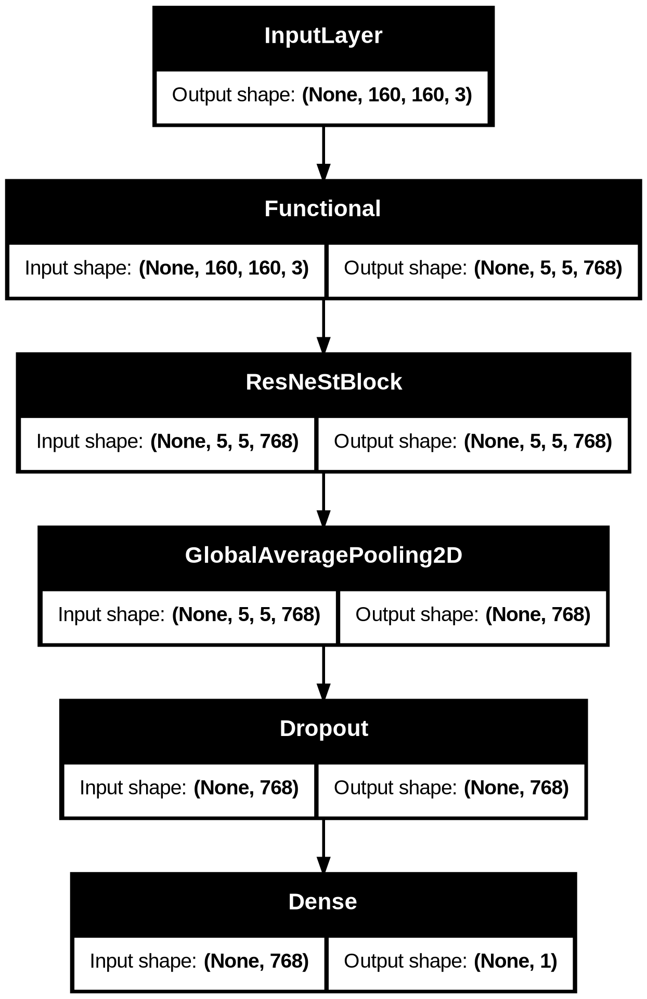

In [ ]:
# [MODIFIED IN REVISION] plot the model that is actually trained
plot_model(hybrid_model, to_file='hybrid_model.png', show_shapes=True, expand_nested=False)


**Training**

In [ ]:

initial_epochs = 25
history = hybrid_model.fit(train_ds_aug,
                    epochs=initial_epochs,
                    validation_data=val_ds,
                    class_weight=class_weight,
                    callbacks = [reduce_lr])


Epoch 1/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 166s 3s/step - accuracy: 0.7809 - auc: 0.8705 - loss: 0.4633 - val_accuracy: 0.6391 - val_auc: 0.8432 - val_loss: 0.6269 - learning_rate: 1.0000e-04
Epoch 2/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 227ms/step - accuracy: 0.8763 - auc: 0.9403 - loss: 0.3129 - val_accuracy: 0.7920 - val_auc: 0.9449 - val_loss: 0.4894 - learning_rate: 1.0000e-04
Epoch 3/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 239ms/step - accuracy: 0.9024 - auc: 0.9656 - loss: 0.2402 - val_accuracy: 0.8502 - val_auc: 0.9818 - val_loss: 0.3685 - learning_rate: 1.0000e-04
Epoch 4/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 11s 243ms/step - accuracy: 0.9188 - auc: 0.9737 - loss: 0.2055 - val_accuracy: 0.8226 - val_auc: 0.9233 - val_loss: 0.3795 - learning_rate: 1.0000e-04
Epoch 5/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 226ms/step - accuracy: 0.9203 - auc: 0.9796 - loss: 0.1848 - val_accuracy: 0.8685 - val_auc: 0.9650 - val_loss: 0.3130 - learning_rate: 1.0000e-04
Epoch 6/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 234ms/step - ac

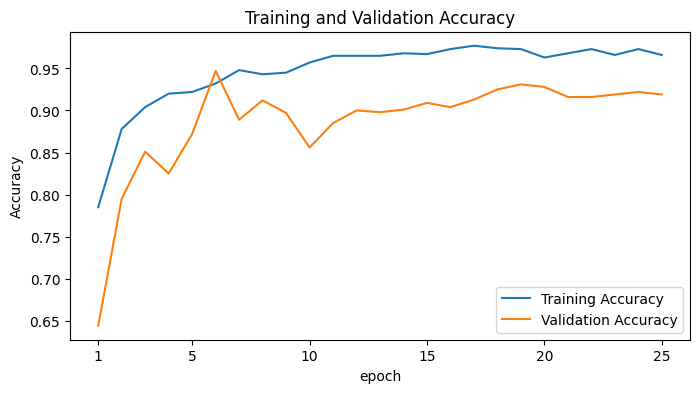

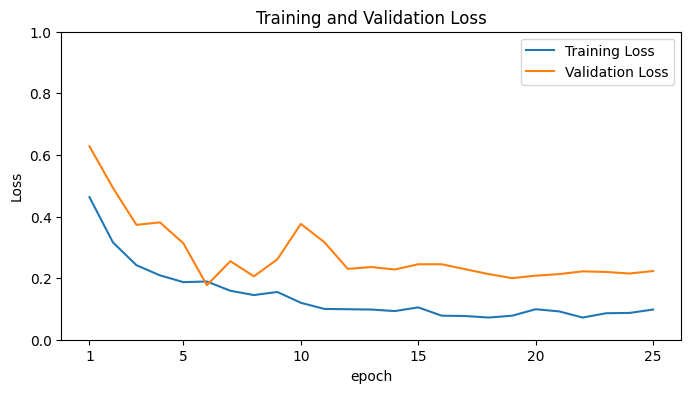

In [ ]:
#view accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)
plt.figure(figsize=(8, 8))

plt.subplot(2, 1, 1)
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()), 1])
plt.xticks([1, 5, 10, 15, 20, 25])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.xlabel('epoch')
plt.ylabel('Loss')
plt.ylim([0, 1.0])
plt.xticks([1, 5, 10, 15, 20, 25])
plt.title('Training and Validation Loss')

plt.tight_layout()
plt.show()

In [ ]:


# Unfreeze ConvNeXt and recompile with a lower learning rate
base_model.trainable = True

hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            threshold=0.0, name='accuracy'
        ),
        tf.keras.metrics.AUC(
            from_logits=True, name='auc'
        )
    ]
)

# Reduce learning rate when validation loss plateaus
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# Stop training if validation loss does not improve
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Fine-tuning
fine_tune_epochs = 100

history_fine = hybrid_model.fit(
    train_ds_aug,
    epochs=initial_epochs + fine_tune_epochs,
    initial_epoch=len(history.epoch),  # Continue from epoch 25
    validation_data=val_ds,
    class_weight=class_weight,
    callbacks=[reduce_lr]
)


Epoch 26/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.9732 - auc: 0.9967 - loss: 0.0727 - val_accuracy: 0.9113 - val_auc: 0.9929 - val_loss: 0.2136 - learning_rate: 1.0000e-05
Epoch 27/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 26s 613ms/step - accuracy: 0.9769 - auc: 0.9945 - loss: 0.0747 - val_accuracy: 0.8838 - val_auc: 0.9862 - val_loss: 0.3518 - learning_rate: 1.0000e-05
Epoch 28/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 25s 586ms/step - accuracy: 0.9799 - auc: 0.9982 - loss: 0.0557 - val_accuracy: 0.9052 - val_auc: 0.9897 - val_loss: 0.2190 - learning_rate: 1.0000e-05
Epoch 29/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 22s 520ms/step - accuracy: 0.9806 - auc: 0.9986 - loss: 0.0494 - val_accuracy: 0.9572 - val_auc: 0.9942 - val_loss: 0.1514 - learning_rate: 1.0000e-05
Epoch 30/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 23s 540ms/step - accuracy: 0.9836 - auc: 0.9984 - loss: 0.0500 - val_accuracy: 0.8960 - val_auc: 0.9892 - val_loss: 0.2387 - learning_rate: 1.0000e-05
Epoch 31/125
42/42 ━━━━━━━━━━━━━━━━━━━━ 24s 564

**VISUALIZE TRAINING**

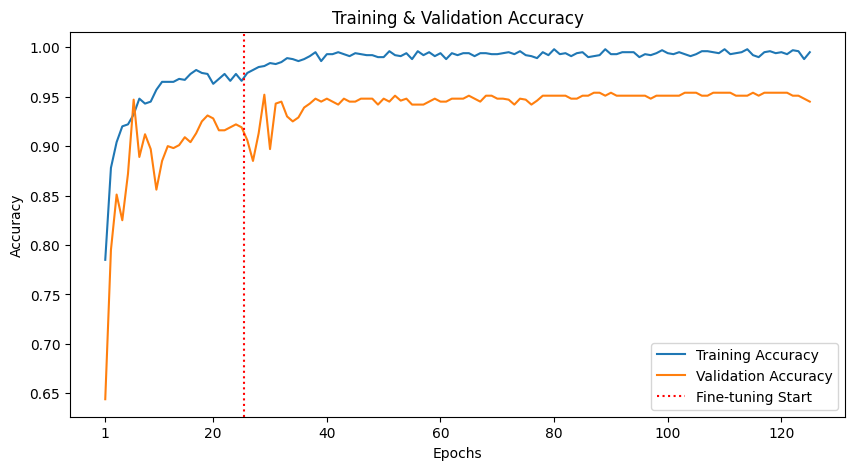

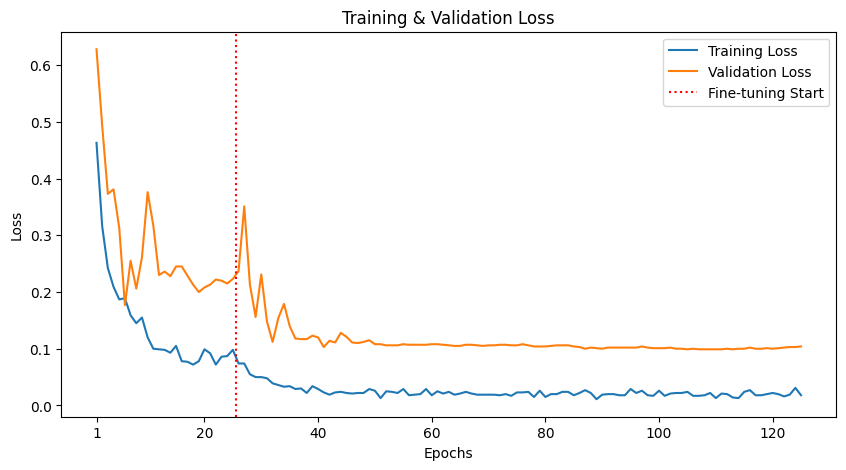

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Join the two training histories
train_accuracy = history.history["accuracy"] + history_fine.history["accuracy"]
val_accuracy   = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
train_loss     = history.history["loss"] + history_fine.history["loss"]
val_loss       = history.history["val_loss"] + history_fine.history["val_loss"]

epochs = np.arange(1, len(train_accuracy) + 1)
fine_tune_epoch = len(history.history["loss"]) + 0.5

# x-axis ticks starting at 1 (instead of 0),
xticks = [1] + list(range(20, len(epochs) + 1, 20))

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_accuracy, label="Training Accuracy", linestyle="-")
plt.plot(epochs, val_accuracy, label="Validation Accuracy", linestyle="-")
plt.axvline(fine_tune_epoch, color="r", linestyle=":", label="Fine-tuning Start")
plt.xticks(xticks)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.savefig("accuracy_combined.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_loss, label="Training Loss", linestyle="-")
plt.plot(epochs, val_loss, label="Validation Loss", linestyle="-")
plt.axvline(fine_tune_epoch, color="r", linestyle=":", label="Fine-tuning Start")
plt.xticks(xticks)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.savefig("loss_combined.png", dpi=300, bbox_inches="tight")
plt.show()


**EVALUATE MODEL PERFORMANCE**

Test images : 449
Test accuracy: 97.33%
Test loss     : 0.1295

Classification report:
              precision    recall  f1-score   support

   Authentic     0.9664    0.9829    0.9746       234
    Tampered     0.9810    0.9628    0.9718       215

    accuracy                         0.9733       449
   macro avg     0.9737    0.9728    0.9732       449
weighted avg     0.9734    0.9733    0.9733       449


Average        Accuracy (%)   Precision (%)   Recall (%)   F1-score (%)
macro                 97.33           97.37        97.28          97.32
weighted              97.33           97.34        97.33          97.33


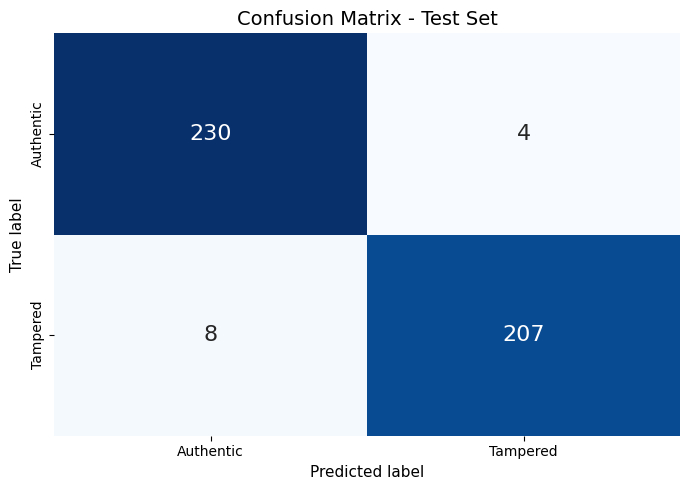

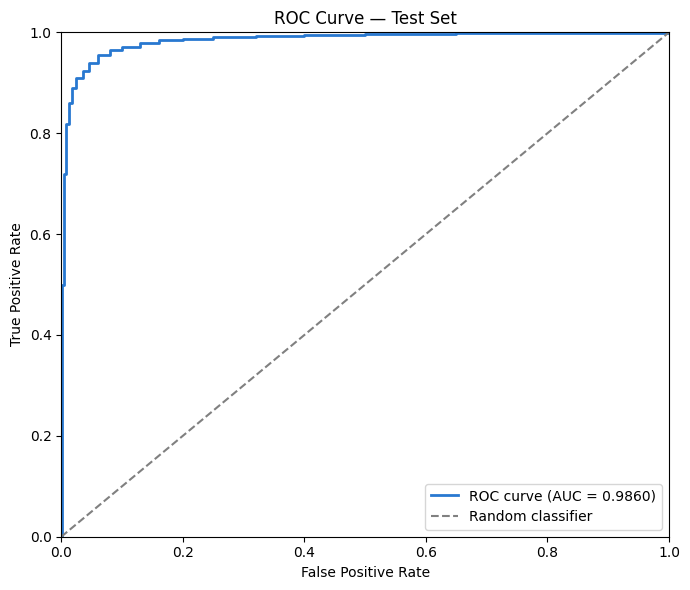

In [ ]:


# FINAL TEST EVALUATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_curve, loss_score, precision_recall_fscore_support)

class_names = ['Authentic', 'Tampered']

# Predictions on the test set
y_true, logits = [], []
for x, yb in test_ds:
    logits.append(hybrid_model.predict(x, verbose=0).ravel())
    y_true.append(yb.numpy())
y_true = np.concatenate(y_true)
logits = np.concatenate(logits)
y_prob = 1 / (1 + np.exp(-logits))
y_pred = (y_prob >= 0.5).astype(int)

# Test accuracy
test_acc = accuracy_score(y_true, y_pred)
test_loss = loss_score(y_true, y_prob)
print(f'Test images : {len(y_true)}')
print(f'Test accuracy: {100 * test_acc:.2f}%')
print(f'Test loss     : {test_loss:.4f}')

# Classification report
print('\nClassification report:')
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Summary table for the manuscript
rows = []
for avg in ['macro', 'weighted']:
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg)
    rows.append({'Average': avg, 'Precision (%)': 100 * p, 'Recall (%)': 100 * r, 'F1-score (%)': 100 * f})
summary = pd.DataFrame(rows).round(2)
summary.insert(1, 'Accuracy (%)', round(100 * test_acc, 2))
summary['AUC'] = round(test_auc, 4)
print(summary.to_string(index=False))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)
tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={'size': 14})
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.savefig('confusion_matrix_test.png', dpi=300, bbox_inches='tight')
plt.show()
# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(5.5, 5.5))
plt.plot(fpr, tpr, lw=2, label=f'ROC curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Test Set')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curve_test.png', dpi=300, bbox_inches='tight')
plt.show()

Predictions:
 [0 0 0 1 0 1 0 0 1 0 0 0 1 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 1]
Labels:
 [0 0 0 1 0 1 0 0 1 0 0 0 1 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 1]


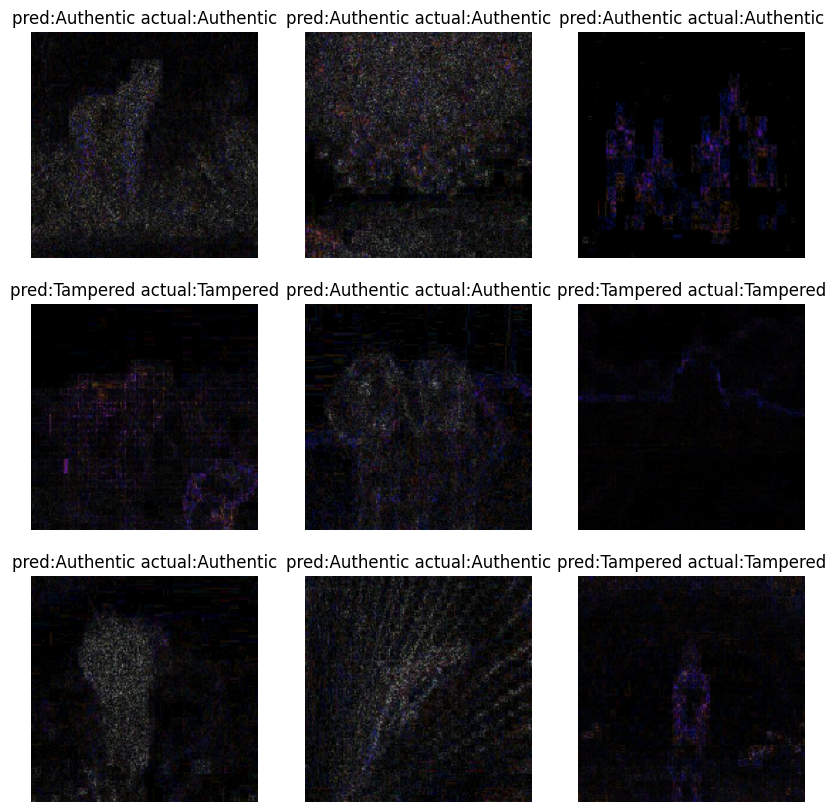

In [ ]:
 #view Predicition

# Retrieve a batch of images from the test set
image_batch, label_batch = val_ds.as_numpy_iterator().next()
predictions = hybrid_model.predict_on_batch(image_batch).flatten()

# Apply a sigmoid since our model returns logits
predictions = tf.nn.sigmoid(predictions)
predictions = tf.where(predictions < 0.5, 0, 1)

print('Predictions:\n', predictions.numpy())
print('Labels:\n', label_batch)

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].astype("uint8"))
  plt.title('pred:'+class_names[predictions[i]]+ ' actual:'+class_names[label_batch[i]])
  plt.axis("off")

## INFERENCE

In [ ]:
import os

# Create the directory if it doesn't exist
if not os.path.exists('/content/drive/MyDrive/model'):
    os.makedirs('/content/drive/MyDrive/model')

# Now save the model
hybrid_model.save('/content/drive/MyDrive/model/my_model.keras')

In [ ]:

loaded_model = tf.keras.models.load_model(
    '/content/drive/MyDrive/model/my_model.keras',
    custom_objects={'ResNeStBlock': ResNeStBlock}
)

In [ ]:
def convert_to_cea_image(path, quality):
    '''
    convert inference image to cea
    '''
    temp_filename = 'temp_file_name.jpg'
    cea_filename = 'temp_cea.png'

    image = Image.open(path).convert('RGB')
    image.save(temp_filename, 'JPEG', quality = quality)
    temp_image = Image.open(temp_filename)

    cea_image = ImageChops.difference(image, temp_image)

    extrema = cea_image.getextrema()
    max_diff = max([ex[1] for ex in extrema])
    if max_diff == 0:
        max_diff = 1
    scale = 255.0 / max_diff

    cea_image = ImageEnhance.Brightness(cea_image).enhance(scale)
    return cea_image

def show_img_file(path):
      '''
      display inference image
      '''
      img_path = pathlib.Path(path)
      img = tf.keras.utils.load_img(img_path, target_size=(160, 160))
      plt.imshow(img)
      plt.axis("off")
      plt.show()

In [ ]:
def predict_img_file(path):
    # try:
        img_path = pathlib.Path(path)
        img = tf.keras.utils.load_img(img_path, target_size=(160, 160))
        img = convert_to_cea_image(path, 90)
        img = img. resize((160, 160))
        img_array = tf.keras.utils.img_to_array(img)
        img_array = preprocess_input(img_array)   # same preprocessing as training
        img_batch = np.expand_dims(img_array, axis=0)
        predictions = loaded_model.predict_on_batch(img_batch).flatten()
        predictions = tf.nn.sigmoid(predictions)
        predictions = tf.where(predictions < 0.5, 0, 1)
        labels = ['Authentic', 'Tampered']
        return  'This picture is {}'.format(labels[predictions.numpy()[0]])

In [ ]:
%%time
path = "/content/gdrive/My Drive/CASIA_2/Authentic/Au_ani_00007.jpg"
predict_img_file(path)


CPU times: user 3.96 s, sys: 112 ms, total: 4.07 s
Wall time: 4.45 s


'This picture is Authentic'

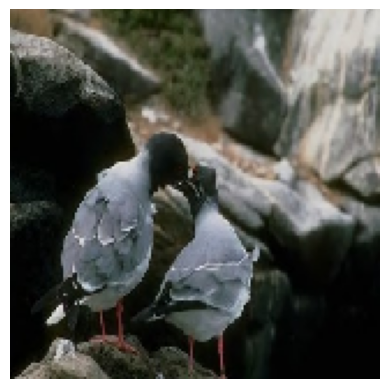

In [ ]:
show_img_file('/content/gdrive/My Drive/CASIA_2/Authentic/Au_ani_00007.jpg')

In [ ]:
%%time
path = "/content/gdrive/My Drive/CASIA_2/Tampered/Tp_D_CND_S_N_txt00028_txt00006_10848.jpg"
predict_img_file(path)


CPU times: user 28.3 ms, sys: 0 ns, total: 28.3 ms
Wall time: 441 ms


'This picture is Tampered'

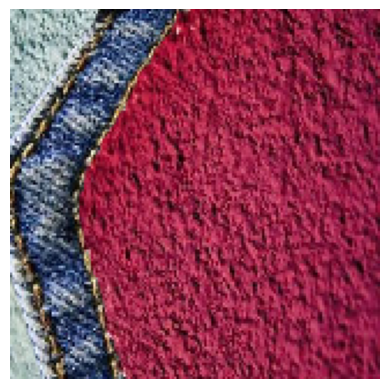

In [ ]:
show_img_file('/content/gdrive/My Drive/CASIA_2/Tampered/Tp_D_CND_S_N_txt00028_txt00006_10848.jpg')

## Grad-CAM

In [ ]:
# Grad-CAM on the ResNeSt block (the last spatial layer before the classifier)
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

def make_gradcam_heatmap_resnest(img_array, model, target='predicted'):
    """Grad-CAM computed on the output of the ResNeSt block (5 x 5 x 768).
    target: 'predicted' = explain the predicted class, 'tampered' or 'authentic' = explain that class."""
    resnest_layer = [l for l in model.layers if isinstance(l, ResNeStBlock)][0]
    grad_model = tf.keras.Model(model.input, [resnest_layer.output, model.output])

    with tf.GradientTape() as tape:
        feature_maps, logits = grad_model(img_array, training=False)
        logit = logits[:, 0]                                  # > 0 means tampered
        if target == 'predicted':
            score = logit if float(logit[0]) >= 0 else -logit
        else:
            score = logit if target == 'tampered' else -logit

    grads = tape.gradient(score, feature_maps)
    weights = tf.reduce_mean(grads, axis=(1, 2))[0]           # one weight per channel
    heatmap = tf.nn.relu(tf.reduce_sum(feature_maps[0] * weights, axis=-1))
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(tf.sigmoid(logit[0]))

def display_gradcam_resnest(image_path, model, alpha=0.4, target='predicted'):
    original_img = np.array(Image.open(image_path).convert("RGB"))

    # the model was trained on CEA images -> CEA image is the model input
    img = convert_to_cea_image(image_path, CEA_QUALITY).resize((160, 160))
    img_array = np.expand_dims(np.array(img).astype("float32"), axis=0)

    heatmap, probability = make_gradcam_heatmap_resnest(img_array, model, target)

    heatmap_resized = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))
    heatmap_color = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET),
                                 cv2.COLOR_BGR2RGB)
    superimposed_img = np.uint8(np.clip(heatmap_color * alpha + original_img * (1 - alpha), 0, 255))

    predicted_class = "Tampered" if probability >= 0.5 else "Authentic"
    confidence = probability if probability >= 0.5 else 1 - probability

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(original_img); plt.title("Original Image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(heatmap_resized, cmap="jet"); plt.title("Grad-CAM Heatmap (ResNeSt block)"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(superimposed_img)
    plt.title(f"Grad-CAM\nPrediction: {predicted_class}\nConfidence: {confidence:.2%}"); plt.axis("off")
    plt.tight_layout()
    plt.show()

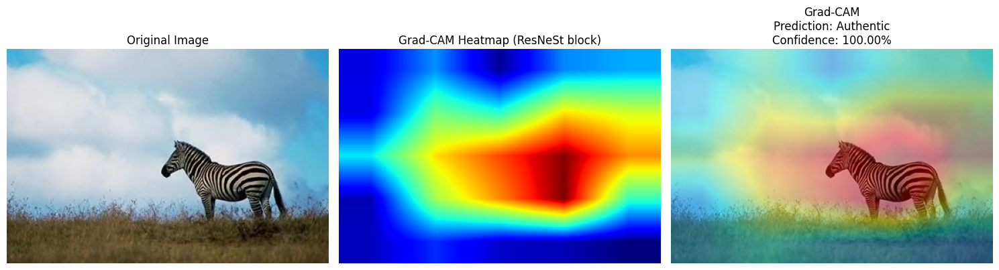

In [ ]:
# Execute Grad-CAM on the ResNeSt block using the correct Google Drive path
image_path = "//content/gdrive/MyDrive/CASIA_2/Authentic/Au_ani_00001.jpg"
display_gradcam_resnest(image_path, hybrid_model)

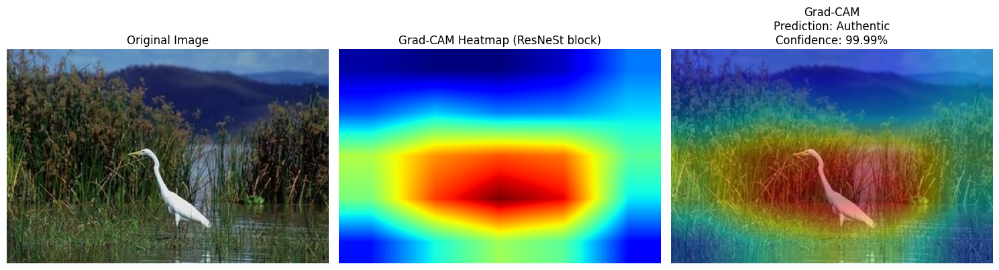

In [ ]:
# Execute Grad-CAM on the ResNeSt block using the correct Google Drive path
image_path = "/content/gdrive/MyDrive/CASIA_2/Authentic/Au_ani_00002.jpg"
display_gradcam_resnest(image_path, hybrid_model)

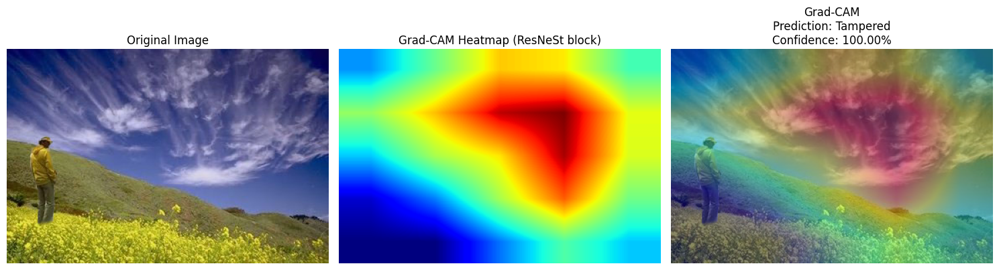

In [ ]:
# Execute Grad-CAM on the ResNeSt block using the correct Google Drive path
image_path = "/content/gdrive/MyDrive/CASIA_2/Tampered/Tp_D_CNN_M_N_nat00013_cha00042_11093.jpg"
display_gradcam_resnest(image_path, hybrid_model)

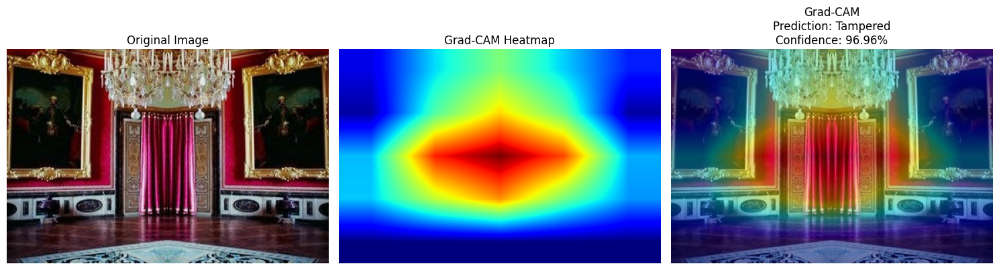

In [ ]:

image_path = "/content/gdrive/My Drive/CASIA_2/Tampered/Tp_D_CNN_M_N_ind00091_ind00091_10648.jpg"
display_gradcam_resnest(image_path, hybrid_model)